In [13]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

import scienceplots
from scipy.integrate import odeint
from multiprocessing import Pool
from tqdm import tqdm
from scipy.io import loadmat
import pandas as pd
from scipy import integrate
from scipy.optimize import fsolve
import operator
import pickle
import hdf5storage
from itertools import permutations
import itertools
import random
import powerlaw
import networkx as nx
import xgi
from matplotlib.patches import FancyArrowPatch

import sys;
sys.path.append("/home/qinjiajie/jupyter_code/2-Tipping_point/High_order_dynamic")

from utils import *
import utils
from importlib import reload
reload(utils)

<module 'utils' from '/home/qinjiajie/jupyter_code/2-Tipping_point/High_order_dynamic/utils.py'>

In [14]:
directory_path = './result_0424/'
result_large_2d = hdf5storage.loadmat(directory_path + 'boundary_collapse.mat')
theory_collapse_tipping = result_large_2d['theory_collapse']

In [15]:
directory_path = './result_0424/'
result_large = hdf5storage.loadmat(directory_path + 'boundary_collapse_origin.mat')
true_collapse_tipping_1 = result_large['true_collapse']

In [16]:
directory_path = './result_0424_1/'
result_large = hdf5storage.loadmat(directory_path + 'boundary_collapse_origin.mat')
true_collapse_tipping_2 = result_large['true_collapse']

In [17]:
true_collapse_tipping = np.vstack((true_collapse_tipping_1, true_collapse_tipping_2))

In [18]:
directory_path = './result_0424/'
result_small_2d = hdf5storage.loadmat(directory_path + 'theory_survive.mat')
theory_survive_tipping = result_small_2d['theory_survive']

In [19]:
directory_path = './result_0424/'
result_small = hdf5storage.loadmat(directory_path + 'true_survive.mat')
true_survive_tipping_1 = result_small['true_survive']

In [20]:
directory_path = './result_0424_1/'
result_small = hdf5storage.loadmat(directory_path + 'true_survive.mat')
true_survive_tipping_2 = result_small['true_survive']

In [21]:
true_survive_tipping = np.vstack((true_survive_tipping_1, true_survive_tipping_2))

In [22]:
import hdf5storage
directory_path = './result_0424_1/'
zz = hdf5storage.loadmat(directory_path + 'zz.mat')
zz = zz['zz1']

def f2_threshold(paras1,paras2,g1, max_tau):
    alpha,beta,gamma,alpha1,beta1,gamma1,rho = paras1
    # d1dt = f*x[0] + g1*alpha*(1-beta*x[0])*gamma*x[0] + g2*alpha1*(1-beta1*x[1])*gamma1*x[1]*rho*x[1]
    
    alpha_2,beta_2,gamma_2,alpha1_2,beta1_2,gamma1_2,rho_2 = paras2

    return g1*alpha*gamma*max_tau


def tau(mu, delta, x):
    tx = 1/(1+np.exp(mu-delta*x)) - 1/(1+np.exp(mu))
    return tx


x = np.arange(0.0001,20,0.0001)
max_tau = np.max(tau(2,1,x)/x)
g1 = 0.1
f2_critical = f2_threshold(zz[0][:7],zz[1][:7],g1,max_tau)

/tmp/ipykernel_38531/363777449.py:105: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


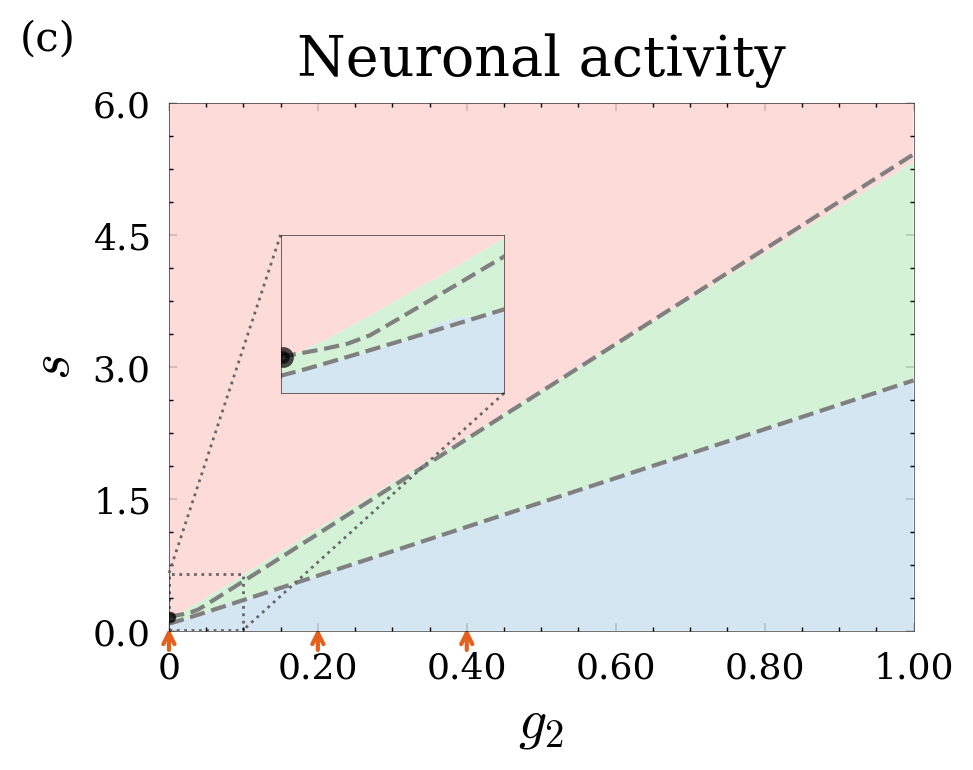

In [23]:
from matplotlib.ticker import MaxNLocator, FuncFormatter
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset
with plt.style.context(['science', 'no-latex']):
    fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(5, 4))
    bwith = 0.2  # 边框宽度设置为2
    ax.spines['bottom'].set_linewidth(bwith)
    ax.spines['left'].set_linewidth(bwith)
    ax.spines['top'].set_linewidth(bwith)
    ax.spines['right'].set_linewidth(bwith)
    
    ax.fill_between(true_survive_tipping[:,0],
                    true_survive_tipping[:,1],
                    0*np.ones(len(true_survive_tipping[:,1])),
                    facecolor='#D4E6F2',label='Actual active area')
    
    ax.fill_between(true_collapse_tipping[:,0],
                    true_collapse_tipping[:,1],
                    true_survive_tipping[:,1],
                    facecolor='#D4F2D5',label='Actual sensitive area')

    ax.fill_between(true_collapse_tipping[:,0],
                    true_collapse_tipping[:,1],
                    6*np.ones(len(true_collapse_tipping[:,1])),
                    facecolor='#FDDBD9',label='Actual inactive area')

    ax.plot(theory_survive_tipping[:,0],theory_survive_tipping[:,1],label='Theoretical active boundary',c='#808080',linewidth =1.5,linestyle='dashed')#d170a8
    ax.plot(theory_collapse_tipping[:,0],theory_collapse_tipping[:,1],label='Theoretical inactive boundary',c='#808080',linewidth =1.5,linestyle='dashed')
    # # ax.autoscale(tight=False)
    ax.scatter(0.001,f2_critical, zorder=4, marker='o', s=10, facecolors='k', edgecolors='k', alpha=0.7, linewidths=1)
    ax.set_ylim([0,6])
    ax.set_xlim([0,1])
    ax.set_xlabel(r'$g_2$',fontsize=20)
    ax.set_ylabel(r'$s$',fontsize=20)
    ax.set_title('Neuronal activity',fontsize=20, pad=10)
    ax.tick_params(width=0.1)
    ax.yaxis.set_major_locator(MaxNLocator(5))
    ax.tick_params(axis='both', labelsize=13, pad=7)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: '0' if abs(x) < 1e-12 else f'{x:.2f}'))
    ax.text(-0.2,1.1,'(c)',fontsize=15,transform=ax.transAxes)
    # ax.legend(frameon=True,facecolor='white',fontsize=9)
    
    # =========================
    # 局部放大图
    # =========================
    axins = inset_axes(
        ax,
        width="30%",      # inset 宽度
        height="30%",     # inset 高度
        loc="lower right", # 位置
        bbox_to_anchor=(-0.55, 0.45, 1, 1),
        bbox_transform=ax.transAxes,
        borderpad=0
    )
    for spine in axins.spines.values():
        spine.set_linewidth(bwith)
    
    # inset 中画同样的数据
    # axins.plot(x, y, lw=1.2)
    axins.fill_between(true_survive_tipping[:,0],
                    true_survive_tipping[:,1],
                    0*np.ones(len(true_survive_tipping[:,1])),facecolor='#D4E6F2')
    
    axins.fill_between(true_collapse_tipping[:,0],
                    true_collapse_tipping[:,1],
                    true_survive_tipping[:,1],
                    facecolor='#D4F2D5')

    axins.fill_between(true_collapse_tipping[:,0],
                    true_collapse_tipping[:,1],
                    6*np.ones(len(true_collapse_tipping[:,1])),
                    facecolor='#FDDBD9')

    axins.plot(theory_survive_tipping[:,0],theory_survive_tipping[:,1],c='#808080',linewidth =1.5,linestyle='dashed') #d170a8
    axins.plot(theory_collapse_tipping[:,0],theory_collapse_tipping[:,1],c='#808080',linewidth =1.5,linestyle='dashed')
    axins.scatter(0.001,f2_critical, zorder=4, marker='o', s=20, facecolors='k', edgecolors='k',linewidths=3,  alpha=0.7)
    
    axins.spines['bottom'].set_linewidth(bwith)
    axins.spines['left'].set_linewidth(bwith)
    axins.spines['top'].set_linewidth(bwith)
    axins.spines['right'].set_linewidth(bwith)
    
    # 设置放大区域范围
    x1, x2 = 0, 0.1
    y1, y2 = 0.01,0.65
    axins.set_xlim(x1, x2)
    axins.set_ylim(y1, y2)
    
    # inset 坐标轴刻度
    axins.tick_params(axis='both', which='both',bottom=False,top=False,left=False,right=False,labelbottom=False,labelleft=False)
    
    # 在主图上标出放大区域，并连接到 inset
    mark_inset(ax, axins,loc1=2, loc2=4, fc="none",ec="0.4",lw=1, ls=":")
    for x0 in [0, 0.2, 0.4]:
        arrow = FancyArrowPatch(
            (x0, -0.047),   # 起点
            (x0, 0.015),    # 终点
            transform=ax.get_xaxis_transform(),
            arrowstyle='->',
            mutation_scale=10,
            linewidth=1.5,
            color='#E5601D',
            clip_on=False
        )
        ax.add_patch(arrow)
plt.tight_layout()
plt.savefig("neuronal_1017.pdf", format='pdf', dpi=600)
plt.show()